In [43]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/Applications/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to 'd04751f9'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/Applications/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '1bce3a99'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/Applications/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '9e27c905'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/olivrwitt/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [2]:
# FINAL CODE
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Import data
fp = os.path.join("data", "Spill_Incidents_20261106.csv")
spills = pd.read_csv(fp)
fp = os.path.join("data", "tl_2026_us_county", "tl_2026_us_county.shp")
counties = gpd.read_file(fp)


# Spills data
# Need to replace spaces with underlines and make all names lowercase
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# The date columns are currently objects, so we need to make them datetimes
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills['received_date'] = pd.to_datetime(spills['received_date'])
spills['close_date'] = pd.to_datetime(spills['close_date'])

# Quantity is an object, and should probably be a float
spills = spills.dropna(subset=['quantity'])
spills['quantity'] = pd.to_numeric(spills['quantity'].astype(str).str.replace(',', ''))

# Select petroleum spills between 1/1/2023 and 12/31/2023
petr_23 = spills[(spills['spill_date'] >= '2023-01-01') & (spills['spill_date'] <= '2023-12-31') & (spills['material_family'] == "Petroleum")]
assert petr_23['material_family'].nunique() == 1
assert petr_23['material_family'].unique()[0] == 'Petroleum'

# Create new data frame listing number of petroleum spills per county in 2023
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index().rename(columns = {'spill_number': 'n_spills'})


# Counties data
# Make the column names lowercase to match the convention of the other dataset
counties.columns = counties.columns.str.lower()

# The dataframe contains state ID information in the form of FIPS codes rather than names
# The FIPS code for New York State is 36
ny_counties = counties[counties['statefp'] == '36']

# Update 'St Lawrence' to 'St. Lawrence'
spills_per_county['county'] = spills_per_county['county'].replace("St Lawrence", "St. Lawrence")
assert "St. Lawrence" in spills_per_county['county'].values


# Merging
# Rename the 'county' value for the Native American reservation rows to match the counties dataset
spills_per_county['county'] = spills_per_county['county'].replace("Onondaga Indian Reservation", "Onondaga")
spills_per_county['county'] = spills_per_county['county'].replace("Tuscarora Indian Reservation", "Niagara")

# Combine these new rows with the existing county groupings
spills_per_county = spills_per_county.groupby('county', as_index=False)['n_spills'].sum()

# Check results
assert "Onondaga Indian Reservation" not in spills_per_county['county'].values
assert "Tuscarora Indian Reservation" not in spills_per_county['county'].values

# Drop results that aren't in New York State
spills_per_county = spills_per_county[spills_per_county['county'].isin(ny_counties['name'])]

# Inner join
ny_spills = pd.merge(ny_counties, spills_per_county, left_on = 'name', right_on = 'county', how='inner')

# Check results
assert len(ny_spills) == len(spills_per_county)


# Mapping
fig, ax = plt.subplots(figsize = (10,8))

# Make plot
ny_spills.plot(
    ax=ax,
    column = 'n_spills',
    cmap='OrRd',   # colormap
    linewidth = 0.5,
    legend = True,
    legend_kwds={
        'label': 'Number of petroleum spills',
        'shrink': 0.6
    }
)

# Set title
ax.set_title('Petroleum Spills per County in New York State, 2023', fontsize=14, fontweight='bold')

# Make sure there is no axis 
ax.set_axis_off()

# Add annotations
ax.annotate(
    'Data Source: New York State Department of Environmental Conservation\n'
    'Date of access: 11/5/2026',
    xy=(0.02, 0.02),
    xycoords='axes fraction',
    fontsize = 8,
    color = 'gray',
    ha='left',
    va='bottom'
)


ax.annotate(
    'Note: Counts for Niagara and Onondaga counties include data\n' \
    'reported by and owned by Native American Nations\n'
    'within those counties.',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    fontsize=8,
    color='gray',
    style='italic',
    ha='left',
    va='top'
)

plt.show()


<Figure size 1000x800 with 2 Axes>

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

### First Dataset: Oil Spills Data
This dataset, saved as a CSV, contains data on oil spills in New York State.  It contains information on the spill location (city/locality, nearest address and zip code, and affected body of water), reason or cause for the spill, information on the spilled material (material name, material family, amount spilled, and source of spill), and information on cleanup (amount of spilled material recovered and spill close date).  The data is sourced from NY open data (data.ny.gov), and was collected/provided by the New York State Department of Environmental Conservation.  It was accessed on November 6, 2026.  The data is updated daily.

### Second Dataset: TIGER Shapefile
This dataset, saved as a shapefile, contains US County-level legal boundaries and lines.  While not used in this project, this dataset also contains geographic entity codes that can be linked to demographic data available at the US Census Bureau.

## 3. Import libraries

In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [59]:
fp = os.path.join("data", "Spill_Incidents_20261106.csv")
spills = pd.read_csv(fp)


fp = os.path.join("data", "tl_2026_us_county", "tl_2026_us_county.shp")
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [46]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [47]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [48]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [49]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

Based on this preliminary exploration, we can see that most columns contain data as "objects", while `Spill Number`, `SWIS Code`, and `DEC Region` are all saved as integers.  Some columns (`Spill Date`, `Close Date`, and `Recieved Date`) will likely need to be converted to datetimes.  `Quantity` should also probably be a float.  Additionally, columns names contain uppercase letters and spaces which is annnoying to work with.  Therefore, our next step should be to make all names lowercase and replaces spaces with underlines (i.e. `Material Family` --> `material_family`).  We can also see that there are only four types of material families, while there are many counties in the dataset.  We can also see that entries in `County` contain county names as well is Native American reservation names and names of regions of nearby areas outside of New York State (`Pennsylvania - Region 7` and `Canada - Region 5`, for example).

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [61]:
# Need to replace spaces with underlines and make all names lowercase
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Check if this worked
spills.columns 

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [ ]:
# The date columns are currently objects, so we need to make them datetimes
# Use pd.to_datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills['received_date'] = pd.to_datetime(spills['received_date'])
spills['close_date'] = pd.to_datetime(spills['close_date'])

In [63]:
# Quantity is an object, and should probably be a float
spills = spills.dropna(subset=['quantity'])
spills['quantity'] = pd.to_numeric(spills['quantity'].astype(str).str.replace(',', ''))

In [65]:
# Check that this worked
spills.dtypes

# It worked!  The dates are now datetimes, and `quantity` is now a float


spill_number                      int64
program_facility_name            object
street_1                         object
street_2                         object
locality                         object
county                           object
zip_code                         object
swis_code                         int64
dec_region                        int64
spill_date               datetime64[ns]
received_date            datetime64[ns]
contributing_factor              object
waterbody                        object
source                           object
close_date               datetime64[ns]
material_name                    object
material_family                  object
quantity                        float64
units                            object
recovered                        object
dtype: object

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [70]:
# Select petroleum spills between 1/1/2023 and 12/31/2023
petr_23 = spills[(spills['spill_date'] >= '2023-01-01') & (spills['spill_date'] <= '2023-12-31') & (spills['material_family'] == "Petroleum")]

# Sanity check
petr_23.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,2023-12-08,Traffic Accident,NaN,Tank Truck,2024-12-18,diesel,Petroleum,300.0,Gallons,0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [ ]:
# Print verification message using f-string
print(f"Years in `petr_23`: {petr_23['spill_date'].dt.year.unique()}")
print(f"Earliest date `petr_23`: {petr_23['spill_date'].min()}")
print(f"Latest date `petr_23`: {petr_23['spill_date'].max()}")

Years in `petr_23`: [2023]
Earliest date `petr_23`: 2023-01-01 00:00:00
Latest date `petr_23`: 2023-12-31 00:00:00


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [74]:
assert petr_23['material_family'].nunique() == 1
assert petr_23['material_family'].unique()[0] == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

These numbers are not the same.  There are more rows in petr_23 than there are unique spills (240 more, specifically).  This shows that petr_23 has more than one row per spill.  This implies that some spills are duplicated.  There is a possibility that there are some spills with multiple components (i.e. one event in one location, but with multiple different spills contributing, such as if several tanks ruptured at the same time or something).  Such an event could show up in the dataset as one "unique" spill, but take up multiple rows.  Additionally, there could be one spill consisting of multiple materials, or simply errors in data cleaning and processing.

In [75]:
print(f"Number of rows in petr_23: {len(petr_23)}")
print(f"Number of unique spills: {petr_23['spill_number'].nunique()}")

Number of rows in petr_23: 8468
Number of unique spills: 8228


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [ ]:
# Create new data frame listing number of petroleum spills per county in 2023
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index().rename(columns = {'spill_number': 'n_spills'})

In [78]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

Looking at the data types of the geo-dataframe's columns, we can see that all columns contain data of the type 'object' (string), except for `ALAND` and `AWATER` (land area and water area, respectively), and the geometry column which contains the geometries.  All columns seem to contain the correct data type for their purpose.  The CRS is NAD83 (EPSG:4269), which is commonly used for Canada and the USA (again, reasonable for this dataset).  Based o the plot, we can see that this geodataframe contains information for all US states and territories, and can be cropped to just New York or the surrounding states for greater accuracy and ease of processing.

In [ ]:
# a. Check the geo-dataframe's head
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [80]:
# b. Check the data types of the columns
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [83]:
# c. Check the geo-dataframe's CRS
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

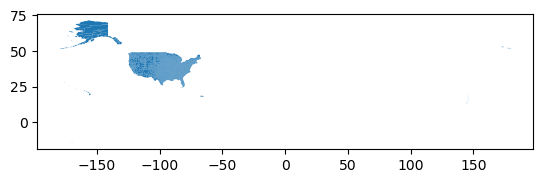

In [86]:
# d. Plot the geo-dataframe
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [88]:
# Make the column names lowercase to match the convention of the other dataset
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [ ]:
# The dataframe contains state ID information in the form of FIPS codes rather than names
# The FIPS code for New York State is 36
ny_counties = counties[counties['statefp'] == '36']

# Check to confirm success
ny_counties.head()

,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
ny_counties['name'].unique()

array(['Erie', 'Niagara', 'Jefferson', 'Steuben', 'Seneca', 'Rensselaer',
       'Albany', 'Saratoga', 'Schoharie', 'Schenectady', 'Ulster',
       'Dutchess', 'Orange', 'Columbia', 'Tompkins', 'Tioga', 'Broome',
       'Cayuga', 'Genesee', 'Onondaga', 'Oswego', 'Madison', 'Livingston',
       'Monroe', 'Ontario', 'Orleans', 'Wayne', 'Chautauqua', 'Sullivan',
       'Chemung', 'Cattaraugus', 'Fulton', 'Montgomery', 'Cortland',
       'Warren', 'Washington', 'Otsego', 'Queens', 'Bronx', 'Nassau',
       'Westchester', 'Richmond', 'Kings', 'Suffolk', 'Rockland',
       'New York', 'Putnam', 'Clinton', 'St. Lawrence', 'Herkimer',
       'Oneida', 'Yates', 'Greene', 'Schuyler', 'Delaware', 'Hamilton',
       'Lewis', 'Allegany', 'Chenango', 'Wyoming', 'Franklin', 'Essex'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [94]:
spills_per_county['county'].unique()

array(['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga',
       'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia',
       'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin',
       'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson',
       'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery',
       'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida',
       'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange',
       'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam',
       'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga',
       'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence',
       'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins',
       'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington',
       'Wayne', 'Westchester', 'Wyoming', 'Yates'], dtype=object)

The counties in `spills_per_county` are listed in alphabetical order, while the counties in `ny_counties` are not.  `spills_per_county` also appears to include more counties than `ny_counties`.  Additionally, `spills_per_county` includes the names of Native American reservations, while `ny_counties` does not.  Finally, `spills_per_county` includes "New Jersey - Region 2" and "Pennsylvania - Region 3", which are not New York counties, and should not be included in the data.

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [97]:
# List counties present in `spills_per_county` but not `ny_counties`
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name']).tolist()
diff_names_spills


['New Jersey - Region 2',
 'Onondaga Indian Reservation',
 'Pennsylvania - Region 3',
 'St Lawrence',
 'Tuscarora Indian Reservation']

In [98]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [100]:
# List counties present in 'ny_counties', but not 'spills_per_county'
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county']).tolist()
diff_names_ny


# It appears that both dataframes contain the county name "St. Lawrence", 
# but 'spills_per_county' spells it "St Lawrence" (without the period).

['St. Lawrence']

In [101]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [106]:
# e. 
print(spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum())
print(spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum())


2
1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [110]:
spills_per_county['county'] = spills_per_county['county'].replace("St Lawrence", "St. Lawrence")

assert "St. Lawrence" in spills_per_county['county'].values

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


According to a google search, the Onondaga Indian Reservation is located in Onondaga County, while the Tuscarora Indian Reservation is located in Niagara County.  We should change those rows so that the county name reads the name of the county that is recognized in the 'counties' dataset.


In [122]:
# a 
# Rename the 'county' value for the Native American reservation rows to match the counties dataset
spills_per_county['county'] = spills_per_county['county'].replace("Onondaga Indian Reservation", "Onondaga")
spills_per_county['county'] = spills_per_county['county'].replace("Tuscarora Indian Reservation", "Niagara")

# Combine these new rows with the existing county groupings
spills_per_county = spills_per_county.groupby('county', as_index=False)['n_spills'].sum()

# Check results
assert "Onondaga Indian Reservation" not in spills_per_county['county'].values
assert "Tuscarora Indian Reservation" not in spills_per_county['county'].values

# Make sure dataframes are now the same length
print(len(ny_counties), len(spills_per_county))

62 64


The dataframes aren't the same length because we didn't account for "New Jersey - Region 2" and "Pennsylvania - Region 3".  We can drop these, since these are not in New York State.

In [127]:
# Drop results that aren't in New York State
spills_per_county = spills_per_county[spills_per_county['county'].isin(ny_counties['name'])]

# Check result
print(len(ny_counties), len(spills_per_county))

62 62


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [126]:
# Inner join
ny_spills = pd.merge(ny_counties, spills_per_county, left_on = 'name', right_on = 'county', how='inner')

# Check results
assert len(ny_spills) == len(spills_per_county)

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [129]:
# New dataframe with only those rows that did not make it to the merged dataset
dropped = spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]
print(dropped)

Empty DataFrame
Columns: [county, n_spills]
Index: []


It looks like no rows were dropped in the inner join.  However, if I had not dropped "Pennsylvania - Region 3" and "New Jersey - Region 2" prior to the merge, these rows would have been dropped in the inner join.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping these records does not affect the map or the reported information, since we are only looking at spills within New York State.  As stated in their names, these records were not within New York State.  Since they occurred in bordering states and were included in a New York database, they were likely tied to or part of events occurring in New York State.  We will still have the records of the part of the event that occurred in New York State, and so dropping these records will not adversely affect our data.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
# I chose to do this step prior to the inner join.  Here is the code: 

# Rename the 'county' value for the Native American reservation rows to match the counties dataset
spills_per_county['county'] = spills_per_county['county'].replace("Onondaga Indian Reservation", "Onondaga")
spills_per_county['county'] = spills_per_county['county'].replace("Tuscarora Indian Reservation", "Niagara")

# Combine these new rows with the existing county groupings
spills_per_county = spills_per_county.groupby('county', as_index=False)['n_spills'].sum()

# Check results using assert
assert "Onondaga Indian Reservation" not in spills_per_county['county'].values
assert "Tuscarora Indian Reservation" not in spills_per_county['county'].values


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



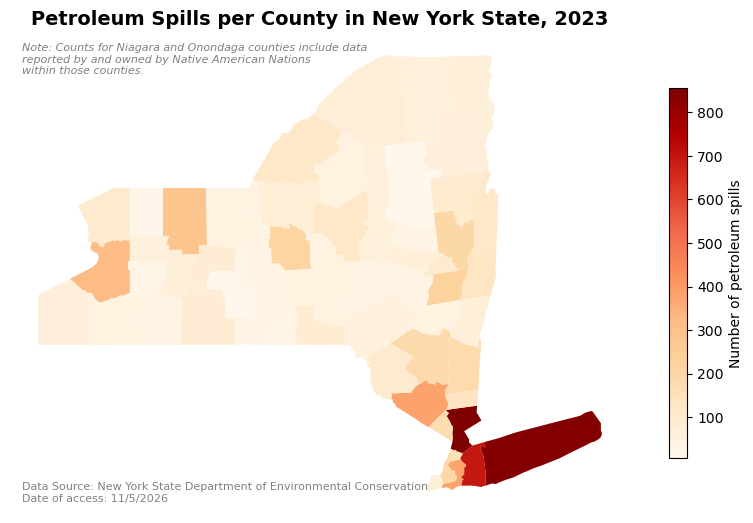

In [142]:
fig, ax = plt.subplots(figsize = (10,8))

# Make plot
ny_spills.plot(
    ax=ax,
    column = 'n_spills',
    cmap='OrRd',   # colormap
    linewidth = 0.5,
    legend = True,
    legend_kwds={
        'label': 'Number of petroleum spills',
        'shrink': 0.6
    }
)

# Set title
ax.set_title('Petroleum Spills per County in New York State, 2023', fontsize=14, fontweight='bold')

# Make sure there is no axis 
ax.set_axis_off()

# Add annotations
ax.annotate(
    'Data Source: New York State Department of Environmental Conservation\n'
    'Date of access: 11/5/2026',
    xy=(0.02, 0.02),
    xycoords='axes fraction',
    fontsize = 8,
    color = 'gray',
    ha='left',
    va='bottom'
)


ax.annotate(
    'Note: Counts for Niagara and Onondaga counties include data\n' \
    'reported by and owned by Native American Nations\n'
    'within those counties.',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    fontsize=8,
    color='gray',
    style='italic',
    ha='left',
    va='top'
)

plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

This map was created using the "matplotlib.pyplot" package.  We plotted the merged result of an inner join between a geodataframe (containing the shapes, borders, and names of counties in New York State) and a dataframe containing counts of petroleum spills in New York State, by county, in 2023.  

For the map aesthetics, I chose to use a yellow/orange/red gradient colormap, since it makes areas with more spills a darker red which reflects the fact that oil spills are a bad event.

The spills reported in the Tuscarora and Onondaga Indian Reservations presented an interesting problem.  I chose to include them in the counts for the counties which the reservations are within.  From a purely numerical standpoint, this makes sense.  However, this violates the CARE Principles for Indigenous Data Governance, since it strips the Indigenous communities of those reservations of their data sovereignty and provenance.  To counteract that, I chose to add a disclaimer to the map stating that the counts for Onondaga and Niagara counties include data from Indigenous Nations within those counties.

Looking at the map, it is clear that the vast majority of spills occurred on Long Island, and other areas near New York City.  This makes sense due to the area's status as a key commerical port, which involves significant ship movement as well as land and sea transport of oil and petroleum products, creating many opportunities for potential spills.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.